# Naloga 1.1 – Praštevila: analiza

Za analizo sem pripravil 3 mini programe, katere poganjamo preko CLI-ja z pomočjo parametrov, da lažje automatiziram samo analizo.

* `vaja1_lcg_test` - Generator naključnih števil
* `vaja1_prime_bench` - Benchmark za tvorbo praštevil z naivno oz. Miller-Rabinovim testom
* `vaja1_keygen_bench` - Tvorba parov ključev RSA
* `vaja1_prime_bench_gmp` in `vaja1_keygen_bench_gmp` - ista programa, le da namesto `cpp_int` uporabljamo GMP

In [12]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Folder with the built executables, None searches the Release build folders below (timings need an optimized build)
BUILD_DIR = None
SEED = 0

ASSIGNMENT_DIR = Path.cwd().resolve().parent
EXE_SUFFIX = ".exe" if sys.platform == "win32" else ""

# vaja1 built on its own, or as part of the whole repository
BUILD_DIR_CANDIDATES = [
    ASSIGNMENT_DIR / "cmake-build-release",
    ASSIGNMENT_DIR.parent / "cmake-build-release" / "vaja1",
]


def find_executable(name: str) -> Path:
    if BUILD_DIR is not None:
        return Path(BUILD_DIR) / f"{name}{EXE_SUFFIX}"
    for folder in BUILD_DIR_CANDIDATES:
        candidate = folder / f"{name}{EXE_SUFFIX}"
        if candidate.exists():
            return candidate
    searched = ", ".join(str(folder) for folder in BUILD_DIR_CANDIDATES)
    raise FileNotFoundError(f"{name} not found in {searched}, build it in the Release profile or set BUILD_DIR")


def run(name: str, *args) -> str:
    exe = find_executable(name)
    result = subprocess.run([str(exe), *map(str, args)], capture_output=True, text=True)
    if result.returncode != 0:
        raise RuntimeError(f"{exe.name} failed with exit code {result.returncode:#x}: {result.stderr.strip()}")
    return result.stdout

## 1. Analiza generatorja naključnih števil

Z generatorjem Super–Duper LCG(2³², 69069, 1, 0) tvorimo 1 milijon naključnih števil z intervala [1, 1000]
in preštejemo, kolikokrat se pojavi posamezno število.

In [13]:
M, A, B = 2**32, 69069, 1
LOW, HIGH = 1, 1000
COUNT = 1_000_000

numbers = np.array(run("vaja1_lcg_test", M, A, B, SEED, LOW, HIGH, COUNT).split(), dtype=np.int64)
values = np.arange(LOW, HIGH + 1)
counts = np.bincount(numbers - LOW, minlength=len(values))

expected = COUNT / len(values)
chi2 = np.sum((counts - expected) ** 2 / expected)

print(f"expected per value: {expected:.2f}")
print(f"min count: {counts.min()} (value {values[counts.argmin()]})")
print(f"max count: {counts.max()} (value {values[counts.argmax()]})")
print(f"standard deviation of counts: {counts.std():.2f}")
print(f"chi-squared: {chi2:.2f} with {len(values) - 1} degrees of freedom")

expected per value: 1000.00
min count: 905 (value 531)
max count: 1089 (value 706)
standard deviation of counts: 31.09
chi-squared: 966.45 with 999 degrees of freedom


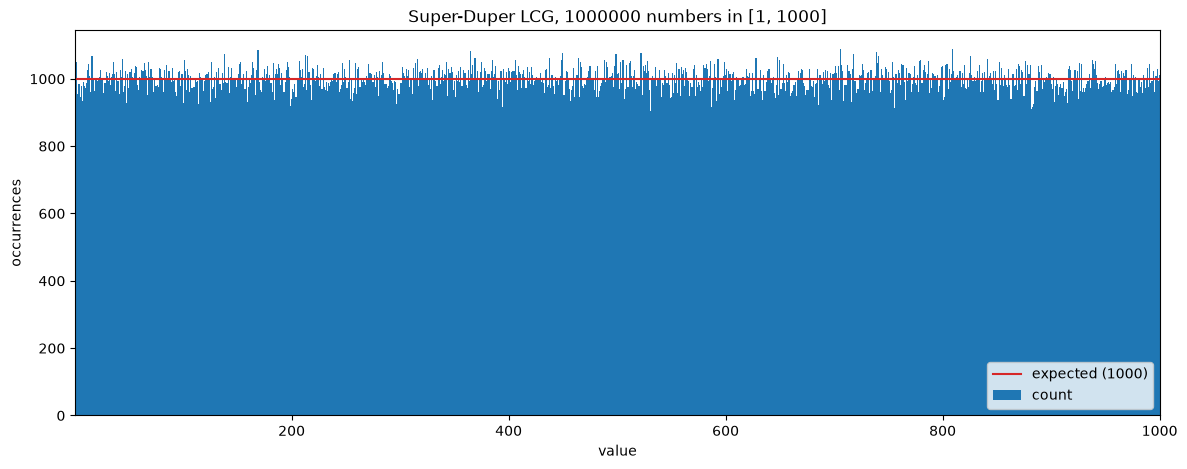

In [14]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(values, counts, width=1.0, color="tab:blue", label="count")
ax.axhline(expected, color="tab:red", label=f"expected ({expected:.0f})")
ax.set_xlim(LOW - 0.5, HIGH + 0.5)
ax.set_xlabel("value")
ax.set_ylabel("occurrences")
ax.set_title(f"Super-Duper LCG, {COUNT} numbers in [{LOW}, {HIGH}]")
ax.legend(loc="lower right")
plt.show()

**Komentar:** Kot vidimo, je distribucija kar dobara. V območju med 950 in navzgor vidimo nekaj šuma, vendar ne predstavlja nekega problema.

## 2. Časovna zahtevnost glede na število bitov

Za vsak n od 4 do 32 tvorimo `REPETITIONS` n-bitnih praštevil z obema metodama in izmerimo povprečni čas tvorbe
enega praštevila. Miller–Rabinov test uporablja `MR_S` ponovitev.

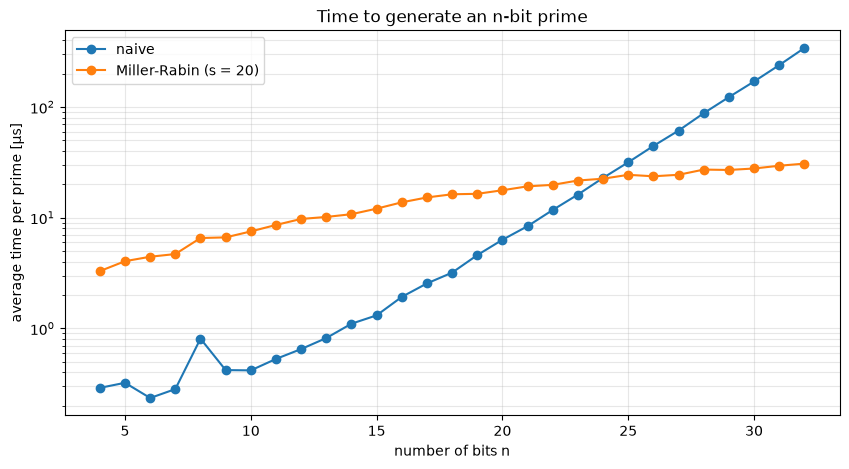

In [15]:
BITS = range(4, 33)
MR_S = 20
REPETITIONS = 1000

naive_times = [float(run("vaja1_prime_bench", "naive", bits, MR_S, REPETITIONS, SEED)) for bits in BITS]
mr_times = [float(run("vaja1_prime_bench", "mr", bits, MR_S, REPETITIONS, SEED)) for bits in BITS]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(BITS, naive_times, marker="o", label="naive")
ax.plot(BITS, mr_times, marker="o", label=f"Miller-Rabin (s = {MR_S})")
ax.set_yscale("log")
ax.set_xlabel("number of bits n")
ax.set_ylabel("average time per prime [µs]")
ax.set_title("Time to generate an n-bit prime")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.show()

**Komentar:** Kot vidimo na grafu, naivni način kar hitro narašča medtem ko miler-rabin ima malo bolj nežno krivuljo naraščanja. Še večja razlika bi se opazila če bi na graf narisali vrednosti od 32 in navzgor, vendar ni realistično da bi naivni način generiral takšno številko.

## 3. Časovna zahtevnost Miller–Rabinovega testa glede na parameter s

Tvorimo 32-bitna praštevila z Miller–Rabinovim testom za s od 1 do 20.

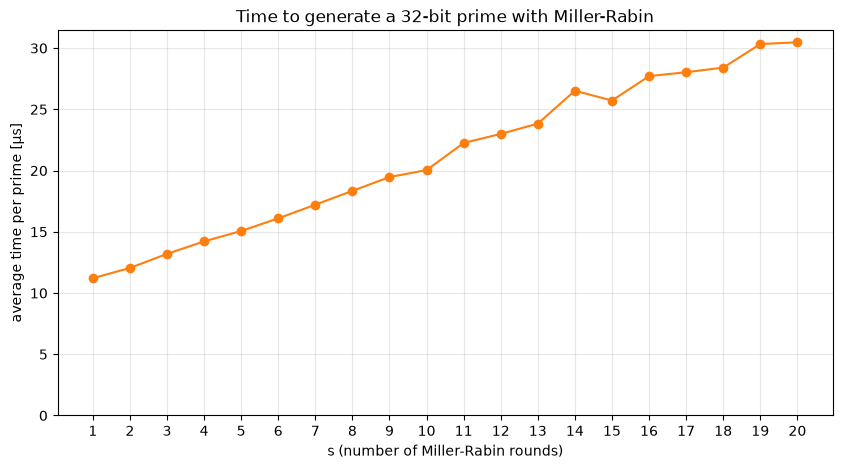

In [16]:
S_VALUES = range(1, 21)
REPETITIONS_S = 10000

s_times = [float(run("vaja1_prime_bench", "mr", 32, s, REPETITIONS_S, SEED)) for s in S_VALUES]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(S_VALUES, s_times, marker="o", color="tab:orange")
ax.set_xticks(list(S_VALUES))
ax.set_ylim(bottom=0)
ax.set_xlabel("s (number of Miller-Rabin rounds)")
ax.set_ylabel("average time per prime [µs]")
ax.set_title("Time to generate a 32-bit prime with Miller-Rabin")
ax.grid(True, alpha=0.3)
plt.show()

**Komentar:** Kot je razvidno iz grafa, več ponovitev kot imamo pri generaciji praštevila, daljše bo trajalo, vendar ni sorazmerno. Torej za s = 1 potrebujemo cca. 10 mikrosekund, kjer za recimo 5 potrebujemo ~13ms. 


## 4. Časovna zahtevnost tvorbe ključev RSA

Program `vaja1_keygen_bench` za vsako število bitov praštevil p in q od 3 do 15 tvori `KEY_REPETITIONS` parov
ključev in izmeri povprečni čas tvorbe enega para. Na os x je nanešeno povprečno število bitov števila n = pq.
Grafikona sta ločena za naivno metodo in za metodo Miller–Rabin.

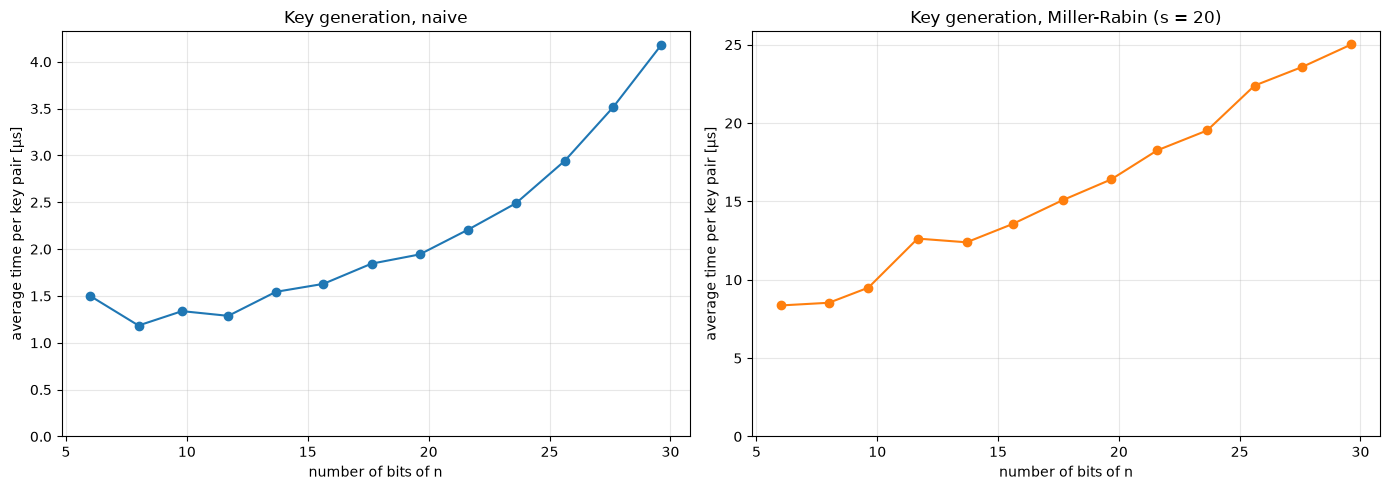

In [22]:
KEY_BITS = range(3, 16)
KEY_REPETITIONS = 1000


def measure_keys(method: str, bits_range=KEY_BITS, repetitions=KEY_REPETITIONS, s: int = 20,
                 exe: str = "vaja1_keygen_bench") -> tuple[list[float], list[float]]:
    """Returns the average bits of n and the average time per key pair for every number of bits of p and q.
    repetitions is either one count for all bits or a list with a count for each number of bits."""
    if isinstance(repetitions, int):
        repetitions = [repetitions] * len(bits_range)
    modulus_bits, times = [], []
    for bits, reps in zip(bits_range, repetitions):
        time, n_bits = map(float, run(exe, method, bits, s, reps, SEED).split())
        modulus_bits.append(n_bits)
        times.append(time)
    return modulus_bits, times


naive_n_bits, naive_key_times = measure_keys("naive")
mr_n_bits, mr_key_times = measure_keys("mr")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, n_bits, times, label, color in [
    (axes[0], naive_n_bits, naive_key_times, "naive", "tab:blue"),
    (axes[1], mr_n_bits, mr_key_times, f"Miller-Rabin (s = {MR_S})", "tab:orange"),
]:
    ax.plot(n_bits, times, marker="o", color=color)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("number of bits of n")
    ax.set_ylabel("average time per key pair [µs]")
    ax.set_title(f"Key generation, {label}")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Komentar:** Pri vrednostih do 30 bitov je naivna metoda hitrejša, vendar pa naivna verzija ni zmožna zgenerirati ključa večjega od 32 bitov oz. je občutno počasnejša, počasi pridemo do nemogoče dolgega časa.

## 5. Velika števila: cpp_int proti GMP

Po implementaciji same naloge me je zanimalo, kako deluje sama Bigint knjižnica. Ob tem sem se spraševal, ali je to
dejansko najhitrejša knjižnica. Prišel sem do tega, da obstaja knjižnica GMP, ki bi lahko bila hitrejša. Zato sem se
odločil še za manjšo analizo oz. primerjavo med knjižnicami.

Programa s končnico `_gmp` izvajata isto kodo, le da namesto `cpp_int` uporabljata GMP (`mpz_int`). Z Miller–Rabinovo
metodo tvorimo praštevila in ključe RSA s p in q od 64 do 1024 bitov. Oba programa z istim semenom tvorita ista
števila, zato opravita popolnoma enako delo.

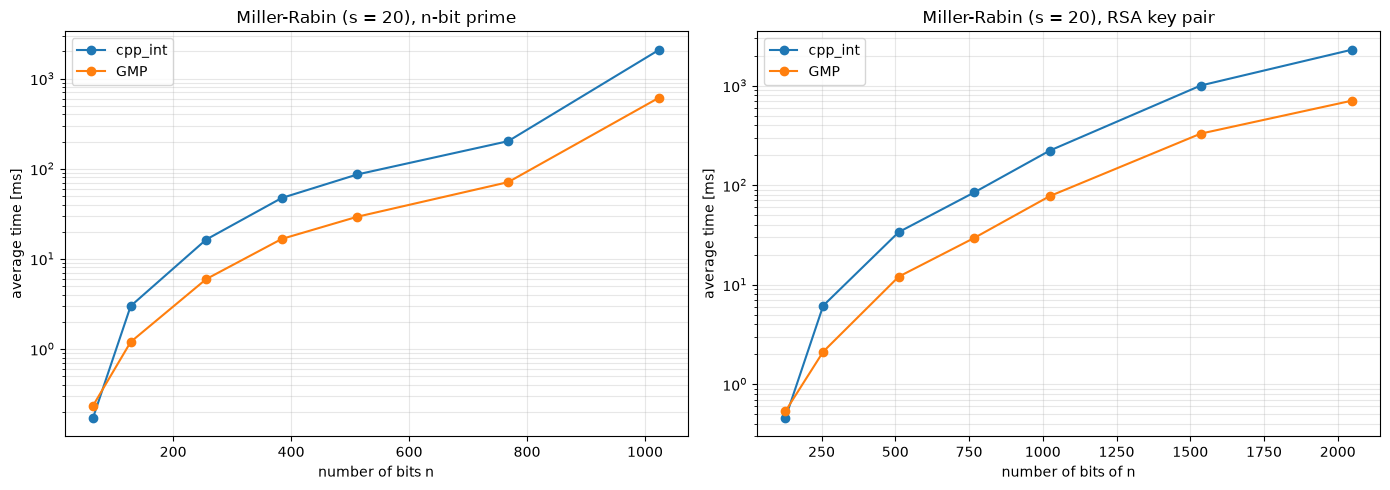

In [18]:
LARGE_BITS = [64, 128, 256, 384, 512, 768, 1024]
# Bigger numbers take much longer, so they get fewer repetitions
LARGE_REPETITIONS = [200, 100, 50, 30, 20, 10, 5]

large_prime_times = [float(run("vaja1_prime_bench", "mr", bits, MR_S, reps, SEED)) for bits, reps in zip(LARGE_BITS, LARGE_REPETITIONS)]
large_prime_gmp_times = [float(run("vaja1_prime_bench_gmp", "mr", bits, MR_S, reps, SEED)) for bits, reps in zip(LARGE_BITS, LARGE_REPETITIONS)]
large_n_bits, large_key_times = measure_keys("mr", LARGE_BITS, LARGE_REPETITIONS, s=MR_S)
_, large_key_gmp_times = measure_keys("mr", LARGE_BITS, LARGE_REPETITIONS, s=MR_S, exe="vaja1_keygen_bench_gmp")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, x, times, gmp_times, xlabel, title in [
    (axes[0], LARGE_BITS, large_prime_times, large_prime_gmp_times, "number of bits n", "n-bit prime"),
    (axes[1], large_n_bits, large_key_times, large_key_gmp_times, "number of bits of n", "RSA key pair"),
]:
    ax.plot(x, np.array(times) / 1000, marker="o", label="cpp_int")
    ax.plot(x, np.array(gmp_times) / 1000, marker="o", label="GMP")
    ax.set_yscale("log")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("average time [ms]")
    ax.set_title(f"Miller-Rabin (s = {MR_S}), {title}")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

prime       0.73x ..  3.40x
key pair    0.85x ..  3.25x


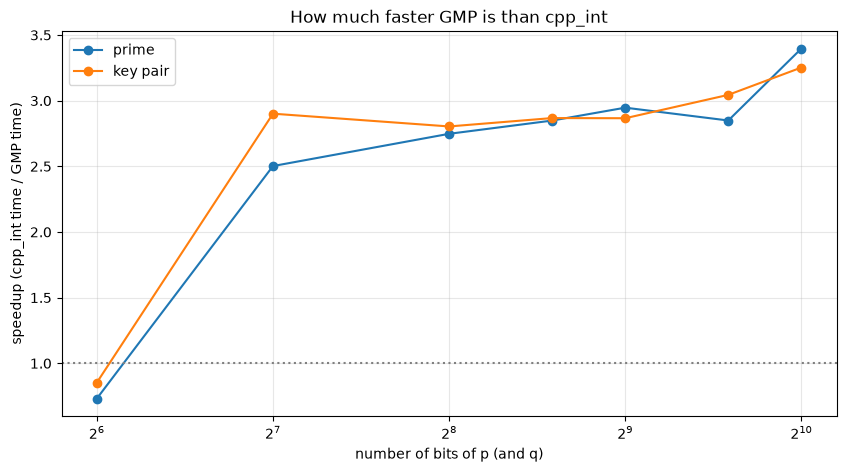

In [19]:
# Speedup of GMP over cpp_int, above 1 means GMP is faster
speedups = [
    ("prime", np.array(large_prime_times) / np.array(large_prime_gmp_times)),
    ("key pair", np.array(large_key_times) / np.array(large_key_gmp_times)),
]

fig, ax = plt.subplots(figsize=(10, 5))
for label, speedup in speedups:
    ax.plot(LARGE_BITS, speedup, marker="o", label=label)
    print(f"{label:10} {speedup.min():5.2f}x .. {speedup.max():5.2f}x")
ax.axhline(1, color="gray", linestyle=":")
ax.set_xscale("log", base=2)
ax.set_xlabel("number of bits of p (and q)")
ax.set_ylabel("speedup (cpp_int time / GMP time)")
ax.set_title("How much faster GMP is than cpp_int")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.show()

**Komentar:** Do 64 bitov je dejansko počasnejša knjižnica GMP, vendar pri 128 začnemo občutiti razliko saj je hitrost generacije pohitrena za vsaj 2.5x. Pri večjih bitih kot recimo 1024 je pa hitrost generacije ključev oz. praštevil več kot 3x hitrejša.